In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

sns.set_theme(style="whitegrid")

In [16]:
df = pd.read_csv("../base/credit_risk_dataset.csv")

df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [17]:
print(f"Quantidade de linhas: {df.shape[0]}")
print(f"Quantidade de colunas: {df.shape[1]}")

df.info()

Quantidade de linhas: 32581
Quantidade de colunas: 12
<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage:

In [18]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [19]:
df.isnull().sum().sort_values(ascending=False)

loan_int_rate                 3116
person_emp_length              895
person_income                    0
person_age                       0
person_home_ownership            0
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [20]:
print(f"Total de registros duplicados: {df.duplicated().sum()}")

Total de registros duplicados: 165


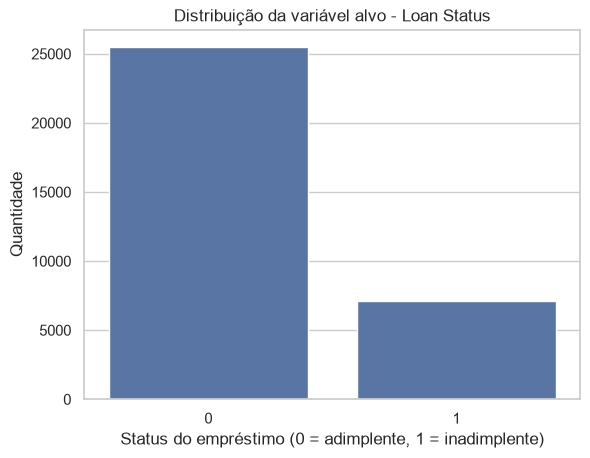

In [21]:
# Distribuição da variável alvo
sns.countplot(data=df, x="loan_status")

plt.title("Distribuição da variável alvo - Loan Status")
plt.xlabel("Status do empréstimo (0 = adimplente, 1 = inadimplente)")
plt.ylabel("Quantidade")
plt.show()

In [22]:
# Percentual de cada classe
df["loan_status"].value_counts(normalize=True) * 100

loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64

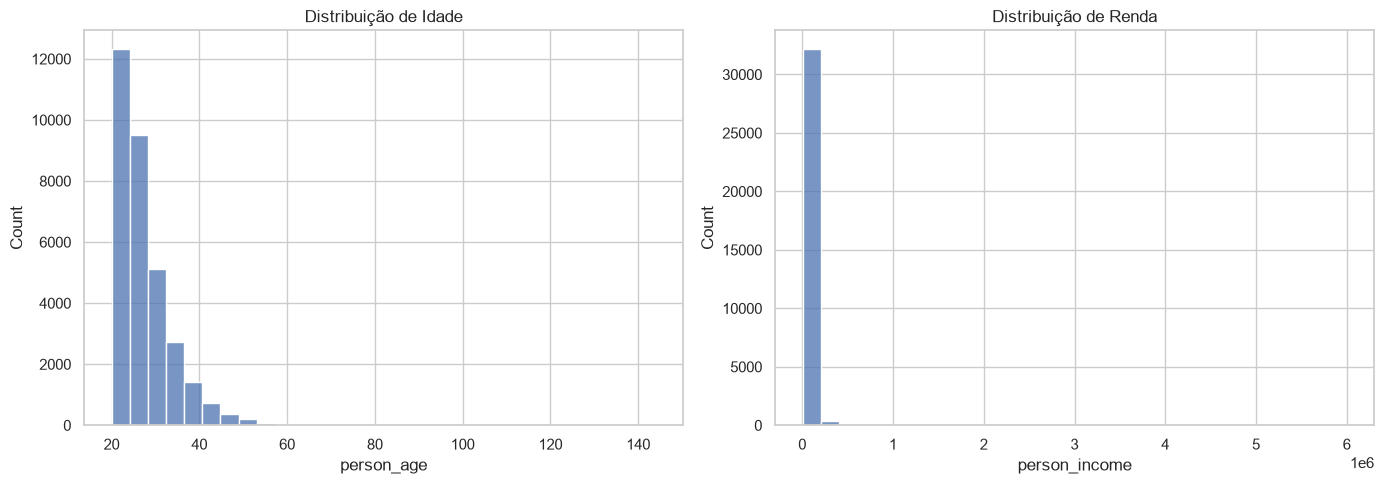

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["person_age"], bins=30, ax=axes[0])
axes[0].set_title("Distribuição de Idade")

sns.histplot(df["person_income"], bins=30, ax=axes[1])
axes[1].set_title("Distribuição de Renda")

plt.tight_layout()
plt.show()

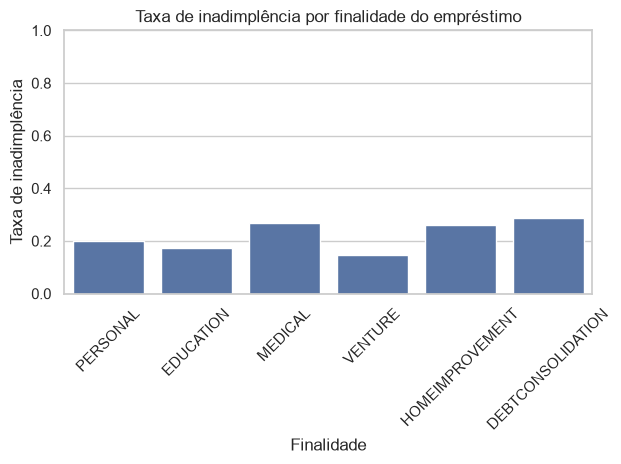

In [26]:
sns.barplot(
    data=df,
    x="loan_intent",
    y="loan_status",
    errorbar=None
)

plt.title("Taxa de inadimplência por finalidade do empréstimo")
plt.xlabel("Finalidade")
plt.ylabel("Taxa de inadimplência")
plt.xticks(rotation=45)
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

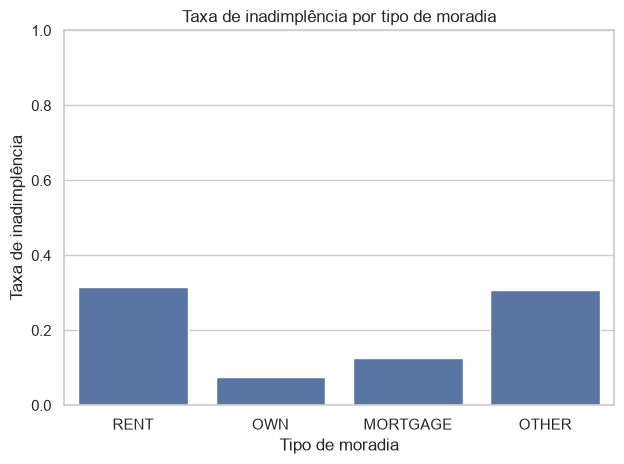

In [27]:
sns.barplot(
    data=df,
    x="person_home_ownership",
    y="loan_status",
    errorbar=None
)

plt.title("Taxa de inadimplência por tipo de moradia")
plt.xlabel("Tipo de moradia")
plt.ylabel("Taxa de inadimplência")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()

In [28]:
colunas = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_percent_income",
    "cb_person_cred_hist_length"
]

df[colunas].describe(
    percentiles=[0.01, 0.05, 0.50, 0.95, 0.99, 0.995]
).T

,count,mean,std,min,1%,5%,50%,95%,99%,99.5%,max
person_age,32581.0,27.734600,6.348078,20.0,21.00,22.00,26.00,40.00,50.0,54.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.0,14400.00,22880.00,55000.00,138000.00,225200.0,300000.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.0,0.00,0.00,4.00,13.00,18.0,19.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.0,1000.00,2000.00,8000.00,24000.00,29800.0,35000.00,35000.00
loan_percent_income,32581.0,0.170203,0.106782,0.0,0.02,0.04,0.15,0.38,0.5,0.53,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.0,2.00,2.00,4.00,14.00,17.0,23.00,30.00


In [29]:
# Identificação de possíveis valores inconsistentes
df_outliers = df[
    (df["person_age"] > 100) |
    (df["person_emp_length"] > 60) |
    (df["person_income"] > 1_000_000)
]

df_outliers[
    ["person_age", "person_income", "person_emp_length",
     "loan_amnt", "loan_percent_income", "loan_status"]
]

,person_age,person_income,person_emp_length,loan_amnt,loan_percent_income,loan_status
0,22,59000,123.0,35000,0.59,1
81,144,250000,4.0,4800,0.02,0
183,144,200000,4.0,6000,0.03,0
210,21,192000,123.0,20000,0.10,0
575,123,80004,2.0,20400,0.25,0
747,123,78000,7.0,20000,0.26,0
17833,32,1200000,1.0,12000,0.01,0
29119,36,1200000,16.0,10000,0.01,0
29120,40,1200000,1.0,10000,0.01,0
30049,42,2039784,0.0,8450,0.00,0


In [30]:
# Quantidade de registros com cada inconsistência

print("Idades acima de 100:", (df["person_age"] > 100).sum())

print("Tempo de emprego acima de 60 anos:",
      (df["person_emp_length"] > 60).sum())

print("Renda acima de R$ 1 milhão:",
      (df["person_income"] > 1_000_000).sum())

print("Total de registros com algum desses problemas:",
      df_outliers.shape[0])

Idades acima de 100: 5
Tempo de emprego acima de 60 anos: 2
Renda acima de R$ 1 milhão: 9
Total de registros com algum desses problemas: 15


In [31]:
# Tratamento de valores claramente inválidos

df.loc[df["person_age"] > 100, "person_age"] = np.nan

df.loc[df["person_emp_length"] > 60, "person_emp_length"] = np.nan

print("Idades inválidas restantes:", (df["person_age"] > 100).sum())
print("Tempo de emprego inválido restante:", (df["person_emp_length"] > 60).sum())
print("Valores ausentes após tratamento:")
print(df[["person_age", "person_emp_length"]].isnull().sum())

Idades inválidas restantes: 0
Tempo de emprego inválido restante: 0
Valores ausentes após tratamento:
person_age             5
person_emp_length    897
dtype: int64


In [32]:
# Investigação de registros duplicados

print("Total de registros duplicados:", df.duplicated().sum())

df[df.duplicated(keep=False)].sort_values(
    by=list(df.columns)
).head(10)

Total de registros duplicados: 165


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
15944,21.0,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
16835,21.0,8088,RENT,NaN,MEDICAL,C,1200,15.23,0,0.15,Y,2
2431,21.0,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
17758,21.0,15600,RENT,0.0,MEDICAL,A,2800,7.40,1,0.18,N,4
2498,21.0,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
17601,21.0,18000,RENT,0.0,DEBTCONSOLIDATION,A,3000,7.90,1,0.17,N,2
1778,21.0,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
17642,21.0,20000,RENT,0.0,MEDICAL,A,2000,NaN,0,0.10,N,3
740,21.0,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3
17283,21.0,21600,OWN,NaN,VENTURE,A,7125,6.99,0,0.33,N,3


In [33]:
# Remoção de registros duplicados
duplicados_antes = df.duplicated().sum()

df = df.drop_duplicates().copy()

duplicados_depois = df.duplicated().sum()

print("Duplicados removidos:", duplicados_antes)
print("Duplicados restantes:", duplicados_depois)
print("Dimensão final da base:", df.shape)

Duplicados removidos: 165
Duplicados restantes: 0
Dimensão final da base: (32416, 12)


In [34]:
# Análise de valores ausentes após limpeza

missing = pd.DataFrame({
    "Valores ausentes": df.isnull().sum(),
    "Percentual (%)": (df.isnull().mean() * 100).round(2)
})

missing = missing[missing["Valores ausentes"] > 0].sort_values(
    "Percentual (%)", ascending=False
)

missing

,Valores ausentes,Percentual (%)
loan_int_rate,3095,9.55
person_emp_length,889,2.74
person_age,5,0.02


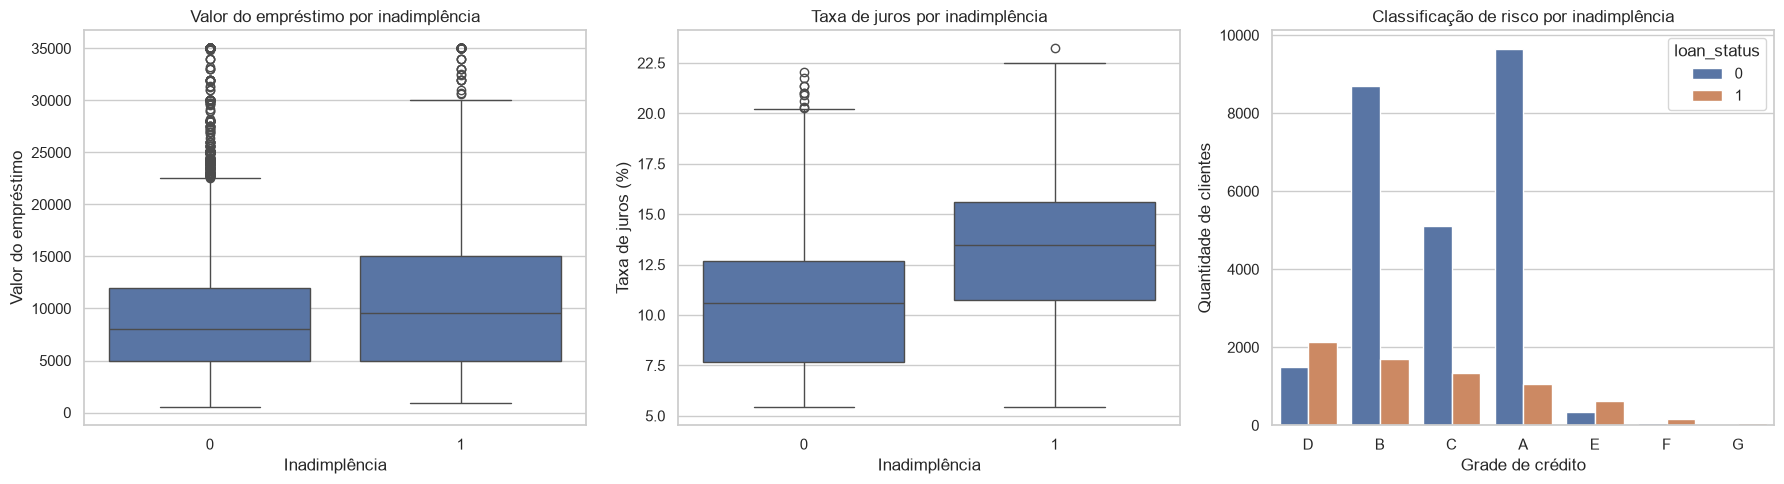

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.boxplot(data=df, x="loan_status", y="loan_amnt", ax=axes[0])
axes[0].set_title("Valor do empréstimo por inadimplência")
axes[0].set_xlabel("Inadimplência")
axes[0].set_ylabel("Valor do empréstimo")

sns.boxplot(data=df, x="loan_status", y="loan_int_rate", ax=axes[1])
axes[1].set_title("Taxa de juros por inadimplência")
axes[1].set_xlabel("Inadimplência")
axes[1].set_ylabel("Taxa de juros (%)")

sns.countplot(data=df, x="loan_grade", hue="loan_status", ax=axes[2])
axes[2].set_title("Classificação de risco por inadimplência")
axes[2].set_xlabel("Grade de crédito")
axes[2].set_ylabel("Quantidade de clientes")

plt.tight_layout()
plt.show()

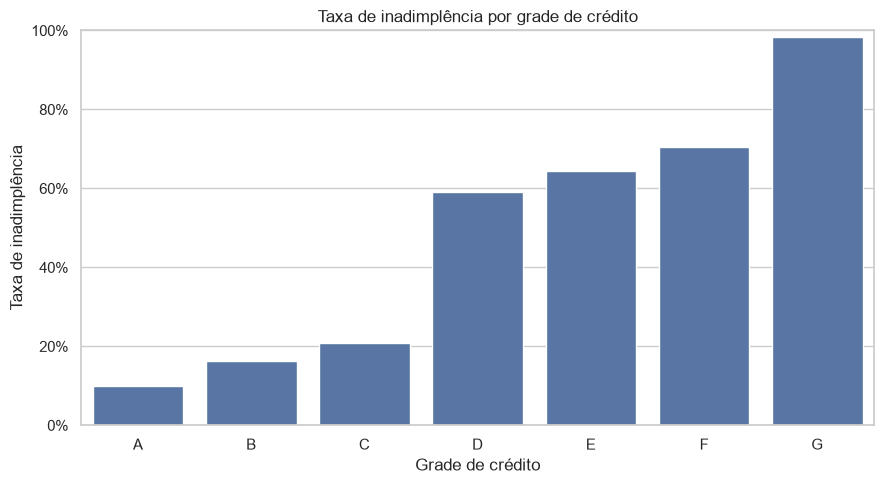

In [36]:
# Taxa de inadimplência por grade de crédito
inadimplencia_grade = df.groupby("loan_grade")["loan_status"].mean().sort_index()

plt.figure(figsize=(9, 5))
sns.barplot(x=inadimplencia_grade.index, y=inadimplencia_grade.values)

plt.title("Taxa de inadimplência por grade de crédito")
plt.xlabel("Grade de crédito")
plt.ylabel("Taxa de inadimplência")
plt.ylim(0, 1)

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0%}")
)

plt.tight_layout()
plt.show()

In [37]:
# Consolidar quantidade de clientes e taxa de inadimplência por grade
resumo_grade = df.groupby("loan_grade")["loan_status"].agg(
    quantidade="count",
    inadimplencia="mean"
)

resumo_grade["inadimplencia"] = (
    resumo_grade["inadimplencia"] * 100
).round(2)

resumo_grade

,quantidade,inadimplencia
loan_grade,,
A,10703,9.96
B,10387,16.32
C,6438,20.75
D,3620,59.06
E,963,64.49
F,241,70.54
G,64,98.44


## Principais achados da análise exploratória

- A base original contém 32.581 registros e 12 variáveis.
- Foram identificados 165 registros duplicados, removidos durante a limpeza.
- Foram encontrados valores inconsistentes nas variáveis `person_age` e `person_emp_length`, tratados como valores ausentes.
- A variável `loan_int_rate` possui aproximadamente 9,55% de valores ausentes, enquanto `person_emp_length` possui 2,74% e `person_age` 0,02% após a limpeza.
- A distribuição da variável alvo apresenta predominância de clientes adimplentes, indicando desbalanceamento entre as classes.
- Clientes inadimplentes apresentam, visualmente, valores de empréstimo e taxas de juros mais elevados.
- A variável `loan_grade` apresenta forte associação com a inadimplência, com aumento expressivo das taxas nas grades de maior risco. A grade G apresentou 98,44% de inadimplência, porém possui apenas 64 registros.
- Os valores extremos de renda foram mantidos, pois não representam necessariamente erros de dados.

### Conclusão

A análise exploratória identificou padrões relevantes associados à inadimplência, além de inconsistências e valores ausentes que exigem tratamento. Os resultados orientam as próximas etapas de preparação dos dados, engenharia de atributos e construção dos modelos de classificação.

In [40]:
from pathlib import Path
import sys

# Adiciona a raiz do projeto ao caminho de importação
raiz_projeto = Path("..").resolve()
sys.path.append(str(raiz_projeto))

from src.features import criar_features

# Teste com a base atual
df_teste = criar_features(df)

print("Feature criada:", "comprometimento_renda" in df_teste.columns)
print("Dataframe original preservado:", "comprometimento_renda" not in df.columns)
print("Valores ausentes na nova feature:", df_teste["comprometimento_renda"].isnull().sum())

df_teste[[
    "loan_amnt",
    "person_income",
    "loan_percent_income",
    "comprometimento_renda"
]].head(10)

Feature criada: True
Dataframe original preservado: True
Valores ausentes na nova feature: 0


,loan_amnt,person_income,loan_percent_income,comprometimento_renda
0,35000,59000,0.59,59.322034
1,1000,9600,0.10,10.416667
2,5500,9600,0.57,57.291667
3,35000,65500,0.53,53.435115
4,35000,54400,0.55,64.338235
5,2500,9900,0.25,25.252525
6,35000,77100,0.45,45.395590
7,35000,78956,0.44,44.328487
8,35000,83000,0.42,42.168675
9,1600,10000,0.16,16.000000


In [41]:
from pathlib import Path
import sys
import importlib

# Adiciona a raiz do projeto ao caminho de importação
raiz_projeto = Path("..").resolve()

if str(raiz_projeto) not in sys.path:
    sys.path.append(str(raiz_projeto))

# Importa e recarrega o módulo
import src.features as features
importlib.reload(features)

criar_features = features.criar_features

# Teste com a base atual
df_teste = criar_features(df)

print("Feature criada:", "comprometimento_renda" in df_teste.columns)
print("Dataframe original preservado:", "comprometimento_renda" not in df.columns)
print("Valores ausentes na nova feature:", df_teste["comprometimento_renda"].isnull().sum())

df_teste[[
    "loan_amnt",
    "person_income",
    "loan_percent_income",
    "comprometimento_renda"
]].head(10)

Feature criada: True
Dataframe original preservado: True
Valores ausentes na nova feature: 0


,loan_amnt,person_income,loan_percent_income,comprometimento_renda
0,35000,59000,0.59,59.322034
1,1000,9600,0.10,10.416667
2,5500,9600,0.57,57.291667
3,35000,65500,0.53,53.435115
4,35000,54400,0.55,64.338235
5,2500,9900,0.25,25.252525
6,35000,77100,0.45,45.395590
7,35000,78956,0.44,44.328487
8,35000,83000,0.42,42.168675
9,1600,10000,0.16,16.000000


In [42]:
# Verificar colunas e tipos de dados
df.dtypes

person_age                    float64
person_income                   int64
person_home_ownership             str
person_emp_length             float64
loan_intent                       str
loan_grade                        str
loan_amnt                       int64
loan_int_rate                 float64
loan_status                     int64
loan_percent_income           float64
cb_person_default_on_file         str
cb_person_cred_hist_length      int64
dtype: object

In [43]:
# Separar variáveis numéricas e categóricas
variaveis_numericas = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
variaveis_categoricas = df.select_dtypes(include=["object"]).columns.tolist()

print("Variáveis numéricas:")
print(variaveis_numericas)

print("\nVariáveis categóricas:")
print(variaveis_categoricas)

Variáveis numéricas:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_cred_hist_length']

Variáveis categóricas:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


C:\Users\Stefano\AppData\Local\Temp\ipykernel_17364\3650166359.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  variaveis_categoricas = df.select_dtypes(include=["object"]).columns.tolist()


In [44]:
# Definição da variável alvo
target = "loan_status"

# Variáveis numéricas
variaveis_numericas = [
    "person_age",
    "person_income",
    "person_emp_length",
    "loan_amnt",
    "loan_int_rate",
    "cb_person_cred_hist_length",
    "comprometimento_renda"
]

# Variáveis categóricas
variaveis_categoricas = [
    "person_home_ownership",
    "loan_intent",
    "cb_person_default_on_file"
]

# Consolidar as variáveis preditoras
features = variaveis_numericas + variaveis_categoricas

print("Target:", target)
print("\nTotal de preditoras:", len(features))
print("\nNuméricas:", len(variaveis_numericas))
print("Categóricas:", len(variaveis_categoricas))
print("\nFeatures selecionadas:")
print(features)

Target: loan_status

Total de preditoras: 10

Numéricas: 7
Categóricas: 3

Features selecionadas:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'cb_person_cred_hist_length', 'comprometimento_renda', 'person_home_ownership', 'loan_intent', 'cb_person_default_on_file']


In [45]:
from sklearn.model_selection import train_test_split

# Aplicar a engenharia de atributos na base
df_modelagem = criar_features(df)

# Separar preditoras e variável alvo
X = df_modelagem[features]
y = df_modelagem[target]

# Separação estratificada: 80% treino e 20% teste
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dimensões:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nDistribuição da variável alvo:")
print("Treino:")
print(y_train.value_counts(normalize=True).sort_index())

print("\nTeste:")
print(y_test.value_counts(normalize=True).sort_index())

Dimensões:
X_train: (25932, 10)
X_test: (6484, 10)
y_train: (25932,)
y_test: (6484,)

Distribuição da variável alvo:
Treino:
loan_status
0    0.781313
1    0.218687
Name: proportion, dtype: float64

Teste:
loan_status
0    0.781308
1    0.218692
Name: proportion, dtype: float64
